In [ ]:
# !pip uninstall tensorflow

In [ ]:
!pip install tensorflow

In [ ]:
!pip install tensorflow-gpu

  Using cached tensorflow-gpu-2.12.0.tar.gz (2.6 kB)
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.


# Image Classification Using VGG - Cat or Dog Kaggle Competition

![catanddog](https://storage.googleapis.com/kaggle-competitions/kaggle/3362/media/woof_meow.jpg)

This is a image classification project from [Cat of Dog Kaggel competition](https://www.kaggle.com/c/dogs-vs-cats/overview/description). In this project, I applied convolutional neural network for image classification. And the end, I also applied VGG-16 convolutional neural network by using transfer learning. VGG-16 is a popular deep learning neural network in computer vision, proposed by K. Simonyan and A. Zisserman from the University of Oxford in the paper “[Very Deep Convolutional Networks for Large-Scale Image Recognition](https://arxiv.org/abs/1409.1556)”. The structrue of VGG 16 network is following:
![VGG](https://neurohive.io/wp-content/uploads/2018/11/vgg16-1-e1542731207177.png)

In [ ]:
import pandas as pd
import IPython.display as display
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import os,random
import matplotlib.pyplot as plt
print(tf.__version__)

2.17.1


## Prepare Data

The dataset has been split into two parts - training set which contains 25,000 images of dags and cats. In this project, the model is trained on the training set and tested on test set which includes 12,500 images. Since uploading the dataset to google colab is time-consuming. [Yura Istomin](https://medium.com/@yuraist/how-to-upload-your-own-dataset-into-google-colab-e228727c87e9) gives me an idea of uploading the dataset to github and cloning the repository, which works perfectly to use the dataset in Google colab.

In [ ]:
! git clone https://github.com/patrick013/Image-Classification-CNN-and-VGG.git

fatal: destination path 'Image-Classification-CNN-and-VGG' already exists and is not an empty directory.


In [ ]:
IMAGE_HEIGHT=128
IMAGE_WIDTH=128
BATCH_SIZE=64
def get_pathframe(path):
  '''
  Get all the images paths and its corresponding labels
  Store them in pandas dataframe
  '''
  filenames = os.listdir(path)
  categories = []
  paths=[]
  for filename in filenames:
    paths.append(path+filename)
    category = filename.split('.')[0]
    if category == 'dog':
      categories.append(1)
    else:
      categories.append(0)

  df= pd.DataFrame({
      'filename': filenames,
      'category': categories,
      'paths':paths
  })
  return df

In [ ]:
df=get_pathframe("Image-Classification-CNN-and-VGG/dataset/dataset/")
df.tail(5)

,filename,category,paths
24995,dog.9367.jpg,1,Image-Classification-CNN-and-VGG/dataset/datas...
24996,dog.5265.jpg,1,Image-Classification-CNN-and-VGG/dataset/datas...
24997,dog.8084.jpg,1,Image-Classification-CNN-and-VGG/dataset/datas...
24998,dog.2698.jpg,1,Image-Classification-CNN-and-VGG/dataset/datas...
24999,dog.5612.jpg,1,Image-Classification-CNN-and-VGG/dataset/datas...


In [ ]:
def load_and_preprocess_image(path):
  '''
  Load each image and resize it to desired shape
  '''
  image = tf.io.read_file(path)
  image = tf.image.decode_jpeg(image, channels=3)
  image = tf.image.resize(image, [IMAGE_WIDTH, IMAGE_HEIGHT])
  image /= 255.0  # normalize to [0,1] range
  return image

def convert_to_tensor(df):
  '''
  Convert each data and labels to tensor
  '''
  path_ds = tf.data.Dataset.from_tensor_slices(df['paths'])
  image_ds = path_ds.map(load_and_preprocess_image)
  # onehot_label=tf.one_hot(tf.cast(df['category'], tf.int64),2) if using softmax
  onehot_label=tf.cast(df['category'], tf.int64)
  label_ds = tf.data.Dataset.from_tensor_slices(onehot_label)

  return image_ds,label_ds

In [ ]:
X,Y=convert_to_tensor(df)
print("Shape of X in data:", X)
print("Shape of Y in data:", Y)

Shape of X in data: <_MapDataset element_spec=TensorSpec(shape=(128, 128, 3), dtype=tf.float32, name=None)>
Shape of Y in data: <_TensorSliceDataset element_spec=TensorSpec(shape=(), dtype=tf.int64, name=None)>


In [ ]:
dataset=tf.data.Dataset.zip((X,Y)).shuffle(buffer_size=2000)
dataset_train=dataset.take(22500)
dataset_test=dataset.skip(22500)

dataset_train=dataset_train.batch(BATCH_SIZE, drop_remainder=True)
dataset_test=dataset_test.batch(BATCH_SIZE, drop_remainder=True)
dataset_train

<_BatchDataset element_spec=(TensorSpec(shape=(64, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(64,), dtype=tf.int64, name=None))>

### Check Images

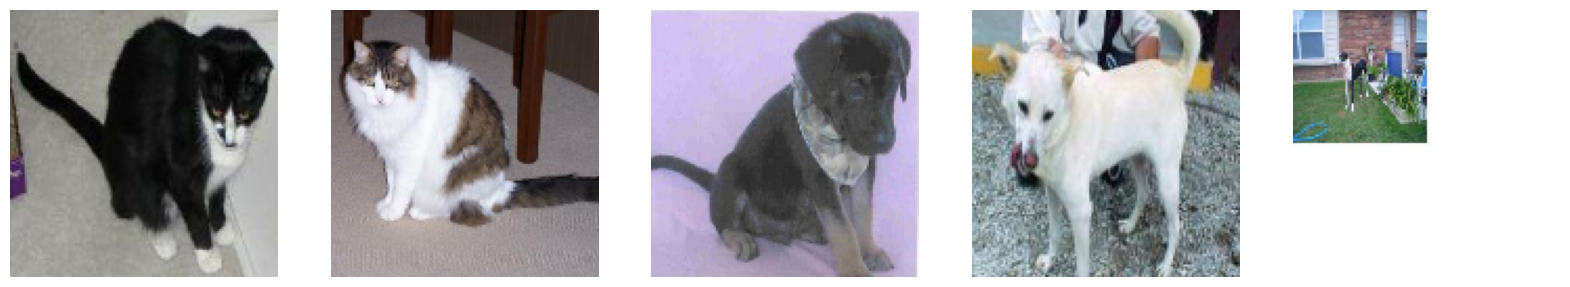

In [ ]:
def plotimages(imagesls):
  fig, axes = plt.subplots(1, 5, figsize=(20,20))
  axes = axes.flatten()
  for image,ax in zip(imagesls, axes):
    ax.imshow(image)
    ax.axis('off')

imagesls=[]
for n, image in enumerate(X.take(5)):
  imagesls.append(image)

plotimages(imagesls)

## Convolutional Neural Networks
### Build Network

The architecture of CNN used in this project is shown as follow (PS: fully connected network is not shown on the picture):
![mynetwork](https://raw.githubusercontent.com/patrick013/Image-Classification-CNN-and-VGG/master/pictures/mycnnmodel.png)

In [ ]:
def My_CNNmodel():

  model = tf.keras.models.Sequential()
  model.add(layers.Conv2D(8, (3, 3), padding='same',activation='relu', input_shape=(IMAGE_WIDTH, IMAGE_HEIGHT, 3)))
  model.add(layers.MaxPooling2D(pool_size=(2,2)))
  model.add(layers.Conv2D(16, (3, 3), padding='same',activation='relu'))
  model.add(layers.MaxPooling2D(pool_size=(2,2)))
  model.add(layers.Conv2D(32, (3, 3), padding='same',activation='relu'))
  model.add(layers.MaxPooling2D(pool_size=(2,2)))
  model.add(layers.Conv2D(64, (3, 3), padding='same',activation='relu'))
  model.add(layers.MaxPooling2D(pool_size=(2,2)))
  model.add(layers.Flatten())
  model.add(layers.Dense(512, activation='relu'))
  model.add(layers.Dense(1, activation='sigmoid'))

  opt=tf.keras.optimizers.Adam(0.001)
  model.compile(optimizer=opt,
              loss='binary_crossentropy', # loss='categorical_crossentropy' if softmax
              metrics=['accuracy'])

  return model

In [ ]:
model=My_CNNmodel()
model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)                    │ (None, 128, 128, 8)         │             224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 64, 64, 8)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 64, 64, 16)          │           1,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 32, 32, 16)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 32, 32, 32)          │           4,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_9 (MaxPooling2D)       │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 4096)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 512)                 │       2,097,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │             513 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,122,705 (8.10 MB)

 Trainable params: 2,122,705 (8.10 MB)

 Non-trainable params: 0 (0.00 B)

### Training

In [ ]:
hist=model.fit(dataset_train,epochs=20,validation_data=dataset_test)

Epoch 1/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 54s 129ms/step - accuracy: 0.6095 - loss: 0.6486 - val_accuracy: 0.7316 - val_loss: 0.5188
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 120ms/step - accuracy: 0.7457 - loss: 0.5134 - val_accuracy: 0.7865 - val_loss: 0.4479
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 81s 117ms/step - accuracy: 0.7889 - loss: 0.4507 - val_accuracy: 0.7696 - val_loss: 0.4831
Epoch 4/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 83s 119ms/step - accuracy: 0.8120 - loss: 0.4100 - val_accuracy: 0.8169 - val_loss: 0.4019
Epoch 5/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 84s 124ms/step - accuracy: 0.8410 - loss: 0.3555 - val_accuracy: 0.8446 - val_loss: 0.3383
Epoch 6/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 43s 118ms/step - accuracy: 0.8616 - loss: 0.3166 - val_accuracy: 0.8690 - val_loss: 0.3058
Epoch 7/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 84s 123ms/step - accuracy: 0.8860 - loss: 0.2670 - val_accuracy: 0.8918 - val_loss: 0.2684
Epoch 8/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 42s 117ms/step - accuracy: 0.9031 - loss: 0

In [ ]:

from google.colab import drive


In [ ]:
model.save("/content/My Drive/model.h5")


In [ ]:
model.save("/content/drive/My Drive/DPprojects/DogvsCats/my_model.h5")


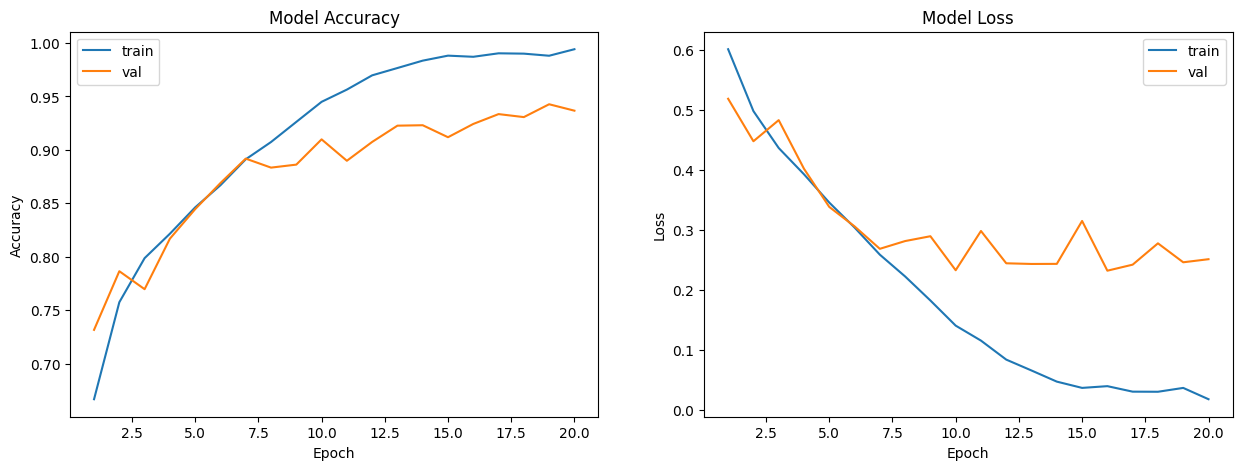

In [ ]:
def plot_model_history(model_history, acc='accuracy', val_acc='val_accuracy'):
    fig, axs = plt.subplots(1,2,figsize=(15,5))
    axs[0].plot(range(1,len(model_history.history[acc])+1),model_history.history[acc])
    axs[0].plot(range(1,len(model_history.history[val_acc])+1),model_history.history[val_acc])
    axs[0].set_title('Model Accuracy')
    axs[0].set_ylabel('Accuracy')
    axs[0].set_xlabel('Epoch')
    #axs[0].set_xticks(np.arange(1,len(model_history.history[acc])+1),len(model_history.history[acc])/10)
    axs[0].legend(['train', 'val'], loc='best')
    axs[1].plot(range(1,len(model_history.history['loss'])+1),model_history.history['loss'])
    axs[1].plot(range(1,len(model_history.history['val_loss'])+1),model_history.history['val_loss'])
    axs[1].set_title('Model Loss')
    axs[1].set_ylabel('Loss')
    axs[1].set_xlabel('Epoch')
    #axs[1].set_xticks(np.arange(1,len(model_history.history['loss'])+1),len(model_history.history['loss'])/10)
    axs[1].legend(['train', 'val'], loc='best')
    plt.show()

plot_model_history(hist)

### Overfitting

Obviously, my model is overfitted! To overcome the problem of overfitting, there are some ways to do:
1. Expand dataset
2. Use regularization
3. Add dropout layers


```
tf.keras.layers.Dropout(0.5)
```
4. Use batchnormalization


```
tf.keras.layers.BatchNormalization()
```



### Evaluation

39/39 ━━━━━━━━━━━━━━━━━━━━ 22s 18ms/step - accuracy: 0.9400 - loss: 0.2211
Test: accuracy = 0.933894  ;  loss = 0.252493 
39/39 ━━━━━━━━━━━━━━━━━━━━ 18s 13ms/step


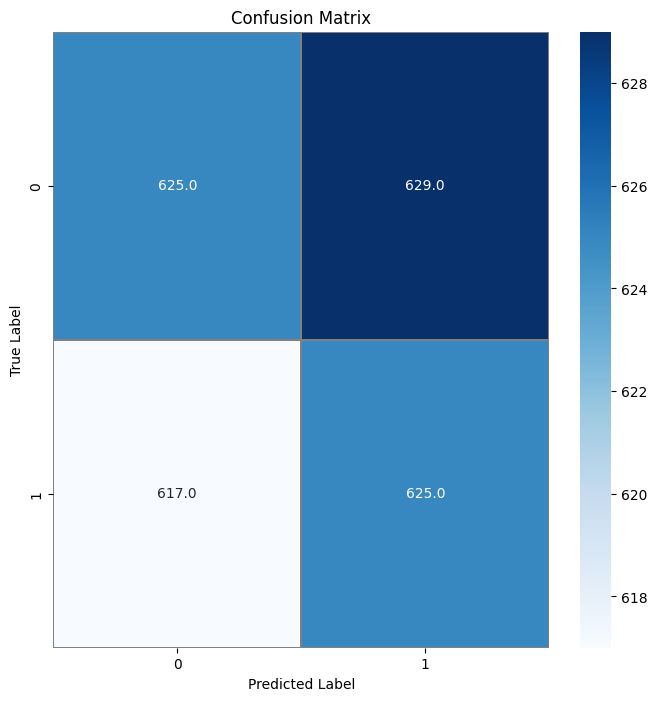

In [ ]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# Evaluate the model
loss, accuracy = model.evaluate(dataset_test)
print("Test: accuracy = %f  ;  loss = %f " % (accuracy, loss))

# Predict the values from the validation dataset
y_pred = model.predict(dataset_test)  # Use predict instead of predict_generator
y_p = np.where(y_pred > 0.5, 1, 0)

# Extract true labels from the test dataset
test_data = dataset_test.unbatch()
y_g = [label.numpy() for _, label in test_data]

# Confusion matrix
confusion_mtx = confusion_matrix(y_g, y_p)
# Plot the confusion matrix
f, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(confusion_mtx, annot=True, linewidths=0.01, cmap="Blues", linecolor="gray", fmt='.1f', ax=ax)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


In [ ]:
# Generate a classification report
report = classification_report(y_g, y_p, target_names=['0','1'])
print(report)

              precision    recall  f1-score   support

           0       0.50      0.50      0.50      1254
           1       0.50      0.50      0.50      1242

    accuracy                           0.50      2496
   macro avg       0.50      0.50      0.50      2496
weighted avg       0.50      0.50      0.50      2496



### Data Augmentation

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

#### Horizontal Flip

Found 21000 images belonging to 2 classes.


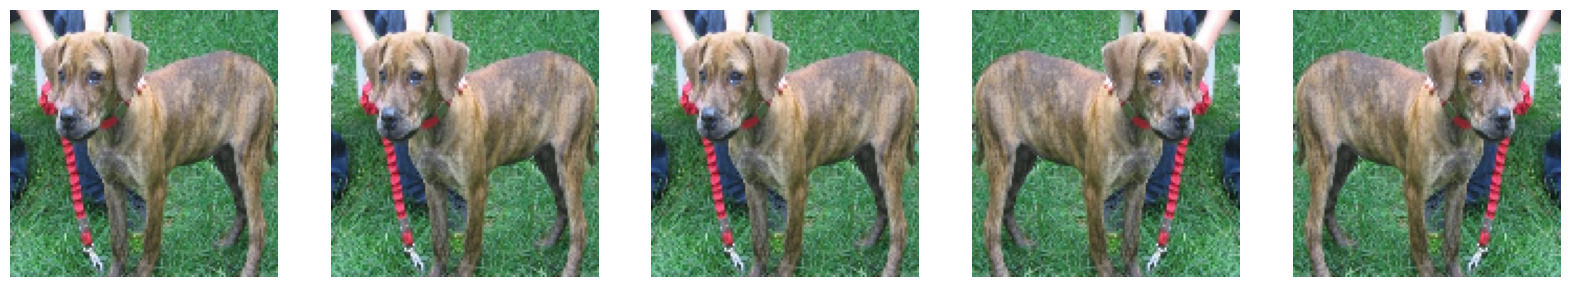

In [ ]:
image_gen_flip = ImageDataGenerator(rescale=1./255, horizontal_flip=True)
train_data_gen = image_gen_flip.flow_from_directory(batch_size=BATCH_SIZE,
                                                    directory="/content/Image-Classification-CNN-and-VGG/dataset/dataset_seperated/train",
                                                    shuffle=True,
                                                    target_size=(IMAGE_HEIGHT, IMAGE_WIDTH))
augmented_images = [train_data_gen[0][0][0] for i in range(5)]
plotimages(augmented_images)

#### Rotation

In [ ]:
image_gen_rotate = ImageDataGenerator(rescale=1./255, rotation_range=45)
train_data_gen = image_gen_rotate.flow_from_directory(batch_size=BATCH_SIZE,
                                                       directory="/content/Image-Classification-CNN-and-VGG/dataset/dataset_seperated/train",
                                                       shuffle=True,
                                                       target_size=(IMAGE_HEIGHT, IMAGE_WIDTH))

augmented_images = [train_data_gen[0][0][0] for i in range(5)]
plotimages(augmented_images)

NameError: name 'ImageDataGenerator' is not defined

#### Zoom Augmentation

Found 21000 images belonging to 2 classes.


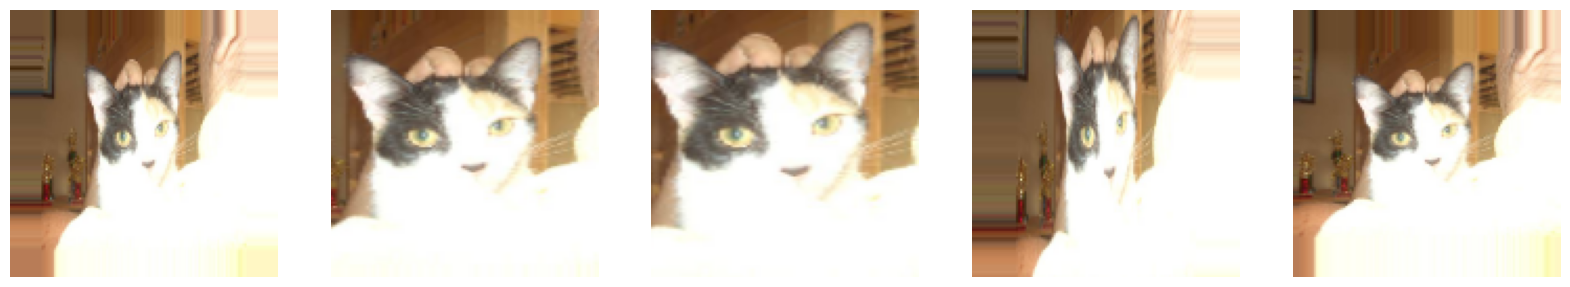

In [ ]:
image_gen_zoom = ImageDataGenerator(rescale=1./255, zoom_range=0.5)
train_data_gen = image_gen_zoom.flow_from_directory(batch_size=BATCH_SIZE,
                                                    directory="/content/Image-Classification-CNN-and-VGG/dataset/dataset_seperated/train",
                                                    shuffle=True,
                                                    target_size=(IMAGE_HEIGHT, IMAGE_WIDTH))

augmented_images = [train_data_gen[0][0][0] for i in range(5)]
plotimages(augmented_images)

#### Pull Together

In [ ]:
image_gen_train = ImageDataGenerator(
                    rescale=1./255,
                    rotation_range=45,
                    width_shift_range=.15,
                    height_shift_range=.15,
                    horizontal_flip=True,
                    zoom_range=0.5
                    )
train_data_gen = image_gen_train.flow_from_directory(batch_size=BATCH_SIZE,
                                                     directory="/content/Image-Classification-CNN-and-VGG/dataset/dataset_seperated/train",
                                                     shuffle=True,
                                                     target_size=(IMAGE_HEIGHT, IMAGE_WIDTH),
                                                     class_mode='binary')
validation_data_gen = image_gen_train.flow_from_directory(batch_size=BATCH_SIZE,
                                                     directory="/content/Image-Classification-CNN-and-VGG/dataset/dataset_seperated/validation",
                                                     shuffle=True,
                                                     target_size=(IMAGE_HEIGHT, IMAGE_WIDTH),
                                                     class_mode='binary')

NameError: name 'ImageDataGenerator' is not defined

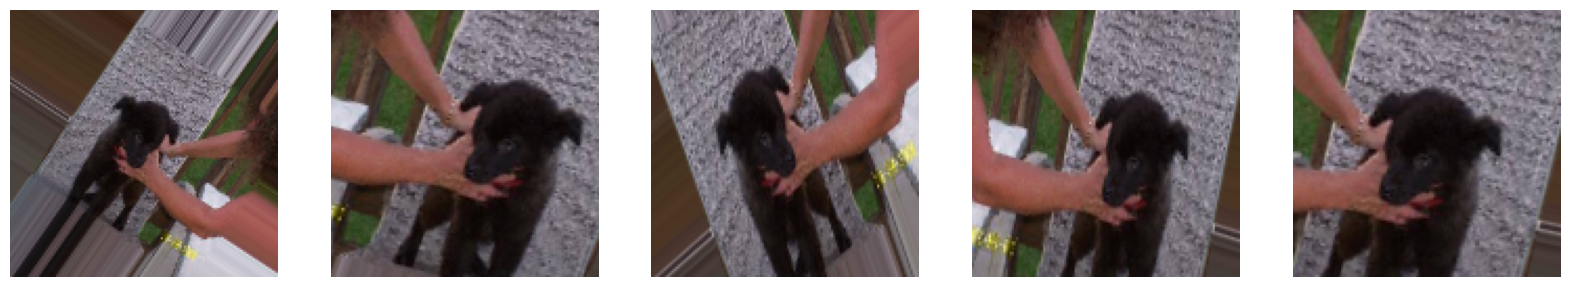

In [ ]:
plotimages([train_data_gen[0][0][0] for i in range(5)])

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers


In [ ]:
# Define the dimensions of the input images
IMAGE_WIDTH = 128  # or the actual width of your images
IMAGE_HEIGHT = 128  # or the actual height of your images

###Retrain

In [ ]:
def Mynew_CNNmodel():

  model = tf.keras.models.Sequential()
  model.add(layers.Conv2D(8, (3, 3), padding='same',activation='relu', input_shape=(IMAGE_WIDTH, IMAGE_HEIGHT, 3)))
  model.add(layers.MaxPooling2D(pool_size=(2,2)))
  model.add(layers.BatchNormalization())
  model.add(layers.Dropout(0.2))
  model.add(layers.Conv2D(32, (3, 3), padding='same',activation='relu'))
  model.add(layers.MaxPooling2D(pool_size=(2,2)))
  model.add(layers.BatchNormalization())
  model.add(layers.Dropout(0.2))
  model.add(layers.Conv2D(64, (3, 3), padding='same',activation='relu'))
  model.add(layers.MaxPooling2D(pool_size=(2,2)))
  model.add(layers.BatchNormalization())
  model.add(layers.Flatten())
  model.add(layers.Dense(512, activation='relu'))
  model.add(layers.Dense(1, activation='sigmoid'))

  opt=tf.keras.optimizers.Adam(0.001)
  model.compile(optimizer=opt,
              loss='binary_crossentropy', # loss='categorical_crossentropy' if softmax
              metrics=['accuracy'])

  return model

In [ ]:

new_model = Mynew_CNNmodel()
new_hist = new_model.fit(
    train_data_gen,  # Replacing fit_generator with fit
    epochs=20,
    validation_data=validation_data_gen
)

/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


NameError: name 'train_data_gen' is not defined

In [ ]:
plot_model_history(new_hist)

NameError: name 'plot_model_history' is not defined

## Transfer Learning - VGG16

The output of dataset should be changed!

In [ ]:
from tensorflow.keras.applications import VGG16

pre_trained_model = VGG16(input_shape=(IMAGE_WIDTH,IMAGE_HEIGHT,3), include_top=False, weights="imagenet")

for layer in pre_trained_model.layers[:15]:
    layer.trainable = False

for layer in pre_trained_model.layers[15:]:
    layer.trainable = True

last_layer = pre_trained_model.get_layer('block5_pool')
last_output = last_layer.output
x = layers.Flatten()(last_output)
x = layers.Dense(512, activation='relu')(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(1, activation='sigmoid')(x)

vggmodel = tf.keras.models.Model(pre_trained_model.input, x)

vggmodel.compile(loss='binary_crossentropy',
              optimizer=tf.keras.optimizers.SGD(lr=1e-4, momentum=0.9),
              metrics=['accuracy'])

vggmodel.summary()

ValueError: Argument(s) not recognized: {'lr': 0.0001}

### Training

In [ ]:
vgghist=vggmodel.fit_generator(dataset_train,epochs=20,validation_data=dataset_test)


AttributeError: 'Functional' object has no attribute 'fit_generator'

In [ ]:
vggmodel.save("/content/drive/My Drive/DPprojects/DogvsCats/vggmodel.h5")

In [ ]:
plot_model_history(vgghist)

### Evaluation


In [ ]:
loss, accuracy = vggmodel.evaluate_generator(dataset_test)
print("Test: accuracy = %f  ;  loss = %f " % (accuracy, loss))

In [ ]:
vgg_y_pred =  model.predict_generator(dataset_test)
vgg_y_p = np.where(vgg_y_pred > 0.5, 1,0)

In [ ]:
# compute the confusion matrix
confusion_mtx = confusion_matrix(y_g, vgg_y_p)
# plot the confusion matrix
f,ax = plt.subplots(figsize=(8, 8))
sns.heatmap(confusion_mtx, annot=True, linewidths=0.01,cmap="Blues",linecolor="gray", fmt= '.1f',ax=ax)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
report = classification_report(y_g, vgg_y_p, target_names=['0','1'])
print(report)

## Summary
Obviously, VGG wins! My model to some degress is overfitted, which means the accuracy on training set is higher than that on validation set. To solve this problem:
1. Batch Normalization
2. Dropout
3. Regularization

### Big Challenge - Loss does not change

The biggest challenge that I met was that there was not a sign that the loss tended to decrease at all after 10 epochs when I was using VGG network. I spent whole night to fix this problem and tried many suggestions online, such as check the dataset labels, reducing the networks and so on. However, it didn't work at all. One of the reason was that I forgot to convert y label to one hot array.